# Lab 11-08 · The Laplace Transform and System Functions

Companion to [chapter 11-08](../../chapters/11-08-laplace-transform-and-system-functions.md). Four parts: the region of convergence computed numerically, geometric evaluation of a frequency response, feedback moving poles, and minimum phase with a link equalizer. Run the cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import quad

## Part 1 — The region of convergence, numerically

Example 11-08.2: $X(s) = 3/[(s + 1)(s - 2)]$ belongs to three signals. For each, integrate $x(t)e^{-\sigma t}$ over a window $[-T, T]$ and let $T$ grow. Inside the ROC the integral settles; outside it grows without bound. The exponents are combined before exponentiating so that nothing overflows.

In [2]:
signals = {
    "causal (sigma > 2)":       {"pos": [(-1, -1), (1, 2)], "neg": []},
    "two-sided (-1 < sigma < 2)": {"pos": [(-1, -1)],         "neg": [(-1, 2)]},
    "anticausal (sigma < -1)":  {"pos": [],                  "neg": [(1, -1), (-1, 2)]},
}

def window_integral(sig, sigma, T):
    fp = lambda t: sum(A * np.exp((a - sigma) * t) for A, a in sig["pos"])
    fn = lambda t: sum(A * np.exp((a - sigma) * t) for A, a in sig["neg"])
    total = 0.0
    if sig["pos"]:
        total += quad(fp, 0, T, limit=200)[0]
    if sig["neg"]:
        total += quad(fn, -T, 0, limit=200)[0]
    return total

X = lambda s: 3 / ((s + 1) * (s - 2))
for name, sig in signals.items():
    print(name)
    for sigma in (-2.0, 0.5, 3.0):
        vals = [window_integral(sig, sigma, T) for T in (5, 10, 20)]
        print(f"   sigma = {sigma:5.1f}: T = 5, 10, 20 ->", np.round(vals, 4), "   X(sigma) =", round(X(sigma), 4))

causal (sigma > 2)
   sigma =  -2.0: T = 5, 10, 20 -> [1.21291151e+08 5.88463167e+16 1.38515560e+34]    X(sigma) = 0.75
   sigma =   0.5: T = 5, 10, 20 -> [1.20402860e+03 2.17934358e+06 7.12431639e+12]    X(sigma) = -1.3333
   sigma =   3.0: T = 5, 10, 20 -> [0.7433 0.75   0.75  ]    X(sigma) = 0.75
two-sided (-1 < sigma < 2)
   sigma =  -2.0: T = 5, 10, 20 -> [-1.47663200e+02 -2.20257158e+04 -4.85165195e+08]    X(sigma) = 0.75
   sigma =   0.5: T = 5, 10, 20 -> [-1.3326 -1.3333 -1.3333]    X(sigma) = -1.3333
   sigma =   3.0: T = 5, 10, 20 -> [-1.47663200e+02 -2.20257158e+04 -4.85165195e+08]    X(sigma) = 0.75
anticausal (sigma < -1)
   sigma =  -2.0: T = 5, 10, 20 -> [0.7433 0.75   0.75  ]    X(sigma) = 0.75
   sigma =   0.5: T = 5, 10, 20 -> [1.20402860e+03 2.17934358e+06 7.12431639e+12]    X(sigma) = -1.3333
   sigma =   3.0: T = 5, 10, 20 -> [1.21291151e+08 5.88463167e+16 1.38515560e+34]    X(sigma) = 0.75


Each signal's integral settles only at the σ inside its own ROC, and there it equals $X(\sigma)$. The two-sided signal at $s = 0.5$:

In [3]:
two = signals["two-sided (-1 < sigma < 2)"]
print("two-sided transform at s = 0.5:", round(window_integral(two, 0.5, 60), 4), " formula:", round(X(0.5), 4))

two-sided transform at s = 0.5: -1.3333  formula: -1.3333


## Part 2 — Geometric evaluation

The series RLC of Example 11-08.4 (capacitor output) has poles at $-10 \pm j30$ krad/s. First the 'rubber sheet' $\lvert H(s)\rvert$ over the s-plane, then the frequency response as a product of pole distances and a sum of pole angles.

poles (krad/s): [-10.+30.j -10.-30.j]


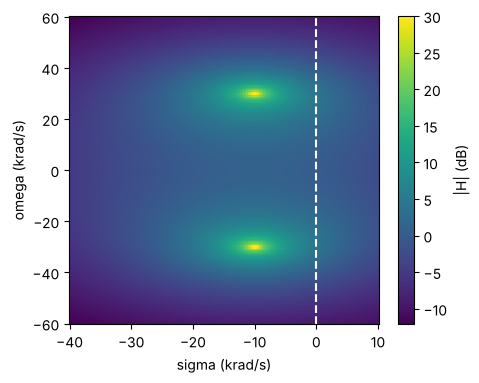

In [4]:
L, C, R = 1e-3, 1e-6, 20.0
poles = np.roots([L * C, R * C, 1])
w0sq = 1 / (L * C)
H = lambda s: w0sq / ((s - poles[0]) * (s - poles[1]))
print("poles (krad/s):", np.round(poles / 1e3, 4))

sg = np.linspace(-40e3, 10e3, 201) + 37.0
wg = np.linspace(-60e3, 60e3, 241) + 53.0
S = sg[None, :] + 1j * wg[:, None]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.pcolormesh(sg / 1e3, wg / 1e3, np.clip(20 * np.log10(np.abs(H(S))), -30, 30), shading="auto")
ax.axvline(0, color="w", ls="--")
ax.set_xlabel("sigma (krad/s)"); ax.set_ylabel("omega (krad/s)")
fig.colorbar(im, ax=ax, label="|H| (dB)")
plt.show()

In [5]:
w = np.linspace(0, 60e3, 601)
dist = np.abs(1j * w[:, None] - poles[None, :])
ang = np.angle(1j * w[:, None] - poles[None, :])
mag_geo = w0sq / dist.prod(axis=1)
ph_geo = -ang.sum(axis=1)
direct = H(1j * w)
print("largest magnitude difference:", np.max(np.abs(mag_geo - np.abs(direct))))
print("largest phase difference (rad):", np.max(np.abs(np.angle(np.exp(1j * (ph_geo - np.angle(direct)))))))
wd = poles.imag.max()
print("at omega_d: distances (krad/s)", np.round(np.abs(1j * wd - poles) / 1e3, 3), " |H| =", round(abs(H(1j * wd)), 4))

largest magnitude difference: 6.661338147750939e-16
largest phase difference (rad): 4.440892098500626e-16
at omega_d: distances (krad/s) [10.    60.828]  |H| = 1.644


## Part 3 — Feedback moves the poles (guided exercise)

**Predict first:** in Example 11-08.3, $H = K/(s^2 + 2s + K)$. As $K$ rises from 1 to 25, what happens to the overshoot, the ringing frequency, and the rate at which the transient dies? Write your prediction, then run the cells.

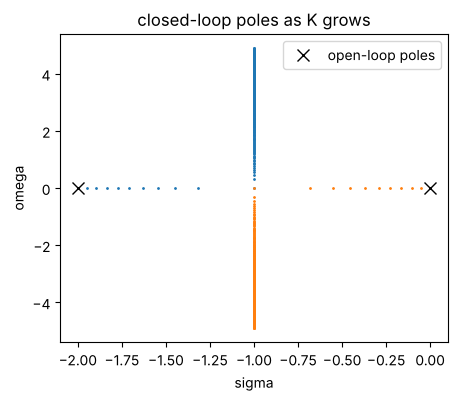

In [6]:
Ks = np.linspace(0.1, 25, 250)
P = np.array([np.roots([1, 2, k]) for k in Ks])
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(P.real, P.imag, ".", ms=2)
ax.plot([0, -2], [0, 0], "kx", ms=8, label="open-loop poles")
ax.set_xlabel("sigma"); ax.set_ylabel("omega"); ax.legend(); ax.set_title("closed-loop poles as K grows")
plt.show()

K =  2: overshoot   4.32 %, ringing 1.000 rad/s (sqrt(K-1) = 1.000)
K =  5: overshoot  20.79 %, ringing 2.000 rad/s (sqrt(K-1) = 2.000)
K = 25: overshoot  52.66 %, ringing 4.899 rad/s (sqrt(K-1) = 4.899)


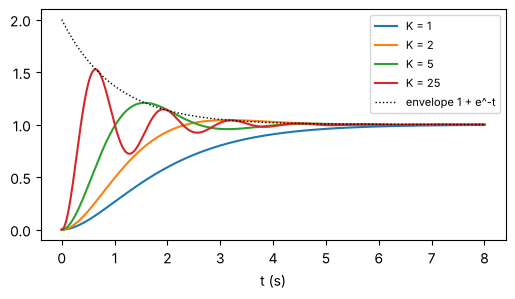

In [7]:
t = np.linspace(0, 8, 8001)
fig, ax = plt.subplots(figsize=(6, 3))
for k in (1, 2, 5, 25):
    _, y = signal.step(([k], [1, 2, k]), T=t)
    ax.plot(t, y, label=f"K = {k}")
    if k > 1:
        pk = np.argmax(y)
        i = np.where(np.diff(np.sign(y - 1)) != 0)[0][:2]
        tc = t[i] - (y[i] - 1) * (t[i + 1] - t[i]) / (y[i + 1] - y[i])   # interpolated crossings of 1
        wd_meas = np.pi / (tc[1] - tc[0])
        print(f"K = {k:2d}: overshoot {100 * (y[pk] - 1):6.2f} %, ringing {wd_meas:.3f} rad/s (sqrt(K-1) = {np.sqrt(k - 1):.3f})")
ax.plot(t, 1 + np.exp(-t), "k:", lw=1, label="envelope 1 + e^-t")
ax.set_xlabel("t (s)"); ax.legend(fontsize=8)
plt.show()

The overshoot rises (20.79% at $K$ = 5, 52.66% at $K$ = 25) and the ringing speeds up as $\sqrt{K - 1}$, but the envelope is $e^{-t}$ for every $K > 1$: the poles move straight up from −1, so their real part, the decay rate, never changes.

## Part 4 — Minimum phase, and a link equalizer

Example 11-08.5: two systems with identical magnitude responses.

non-minimum-phase undershoot: -0.07143 at t = 0.1542 s; minimum-phase minimum: 0.00000


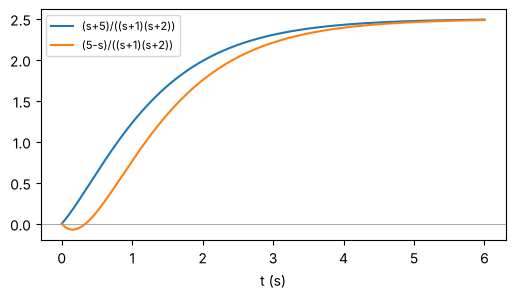

In [8]:
t = np.linspace(0, 6, 60001)
_, y1 = signal.step(([1, 5], [1, 3, 2]), T=t)
_, y2 = signal.step(([-1, 5], [1, 3, 2]), T=t)
i = np.argmin(y2)
print(f"non-minimum-phase undershoot: {y2[i]:.5f} at t = {t[i]:.4f} s; minimum-phase minimum: {y1.min():.5f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t, y1, label="(s+5)/((s+1)(s+2))")
ax.plot(t, y2, label="(5-s)/((s+1)(s+2))")
ax.axhline(0, color="0.6", lw=0.6); ax.legend(fontsize=8); ax.set_xlabel("t (s)")
plt.show()

The IEEE 802.3ck reference CTLE (Example 11-08.6, R-189): $H(f) = (G + jf/f_z)/[(1 + jf/f_{p1})(1 + jf/f_{p2})]$ with $f_z = f_{p1}$ = 21.25 GHz, $f_{p2}$ = 53.125 GHz. Tabulate the DC gain, Nyquist gain and boost for every setting.

In [9]:
fz = fp1 = 21.25e9; fp2 = 53.125e9; fN = 53.125e9 / 2
def ctle(f, g):
    G = 10 ** (g / 20)
    return (G + 1j * f / fz) / ((1 + 1j * f / fp1) * (1 + 1j * f / fp2))
print(" g_DC   zero(GHz)  Nyquist(dB)  boost(dB)")
for g in range(0, -21, -1):
    nyq = 20 * np.log10(abs(ctle(fN, g)))
    print(f"{g:5d}   {10 ** (g / 20) * fz / 1e9:8.3f}   {nyq:9.3f}   {nyq - g:8.3f}")

 g_DC   zero(GHz)  Nyquist(dB)  boost(dB)
    0     21.250      -0.969     -0.969
   -1     18.939      -1.332     -0.332
   -2     16.879      -1.644      0.356
   -3     15.044      -1.909      1.091
   -4     13.408      -2.132      1.868
   -5     11.950      -2.317      2.683
   -6     10.650      -2.470      3.530
   -7      9.492      -2.596      4.404
   -8      8.460      -2.698      5.302
   -9      7.540      -2.781      6.219
  -10      6.720      -2.848      7.152
  -11      5.989      -2.902      8.098
  -12      5.338      -2.946      9.054
  -13      4.757      -2.980     10.020
  -14      4.240      -3.008     10.992
  -15      3.779      -3.031     11.969
  -16      3.368      -3.048     12.952
  -17      3.002      -3.062     13.938
  -18      2.675      -3.074     14.926
  -19      2.384      -3.083     15.917
  -20      2.125      -3.090     16.910


The boost is slightly negative at −1 dB, first positive at −2 dB, and approaches $\lvert g_{DC}\rvert - 3.1$ dB at the deep settings (16.91 dB at −20 dB): the knob lowers the low-frequency gain while the poles hold the high-frequency gain near −3 dB.